## Customer Segmentation & Retention Analysis: Olist E-commerce
Author: Rohit Singh · [GitHub](https://github.com/rohit9354rajput/olist-ecommerce-analytics) · [LinkedIn](https://www.linkedin.com/in/rohit-singh-386755257)

This notebook analyses a Brazilian marketplace with SQL only (PostgreSQL). Python is used just to run the queries and draw the charts.

Three business questions:

1. Who are the best customers, and who is about to leave? (RFM segmentation)
2. How many customers come back to buy again? (cohort retention)
3. How does revenue evolve month after month? (growth with LAG())
The full set of .sql files and a French README are in the GitHub repository: olist-sql-analyse-clients.

Data: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce/code) (licence CC BY-NC-SA 4.0). To run this notebook, attach the dataset with Add Input.

## Method: the choices that matter
**Real customers.** customer_id changes with every order. Only customer_unique_id identifies a person, so it is used for everything customer-related.

**Delivered orders only (about 97% of orders).** Cancelled or unavailable orders generated no real revenue.

**Revenue** = sum of item prices, freight excluded.

**Recency reference date** = the date of the last order in the dataset, not today's date (otherwise every recency would be about eight years).

**Frequency: no NTILE.** More than 95% of customers bought only once, so cutting identical customers into five groups would be arbitrary. Rule used: 2 orders or more = loyal customer.

**Segment thresholds are my own choices,** not a statistical truth.

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

In [102]:
engine = create_engine(
    "postgresql+psycopg://postgres:root"
    "@localhost:5432/olist_ecommerce"
)

In [103]:
def q(sql):
    return display(pd.read_sql_query(sql, engine.connect()))

In [104]:
q("SELECT * FROM customers;")

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


In [105]:
q("""
SELECT
    relname AS table_name,
    n_live_tup AS row_count
FROM pg_stat_user_tables;
""")

,table_name,row_count
0,orders,99441
1,product_category,71
2,payments,103886
3,order_items,112650
4,customers,99441
5,reviews,99224
6,products,32951
7,geolocation,19015
8,sellers,3095


In [106]:
# The trap: customer_id vs customer_unique_id
q("""
SELECT COUNT(*) AS n_orders,
       COUNT(DISTINCT customer_unique_id) AS n_real_customers
FROM customers;
""")

,n_orders,n_real_customers
0,99441,96096


Roughly 99,441 orders for 96,096 real customers: the gap comes from people who came back to buy again.

In [107]:
q("""
SELECT order_status,
       COUNT(*) AS n_orders,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders), 2) AS pct
FROM orders
GROUP BY order_status
ORDER BY n_orders DESC;
""")

,order_status,n_orders,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


Total delivered revenue: 13,221,498.11 BRL


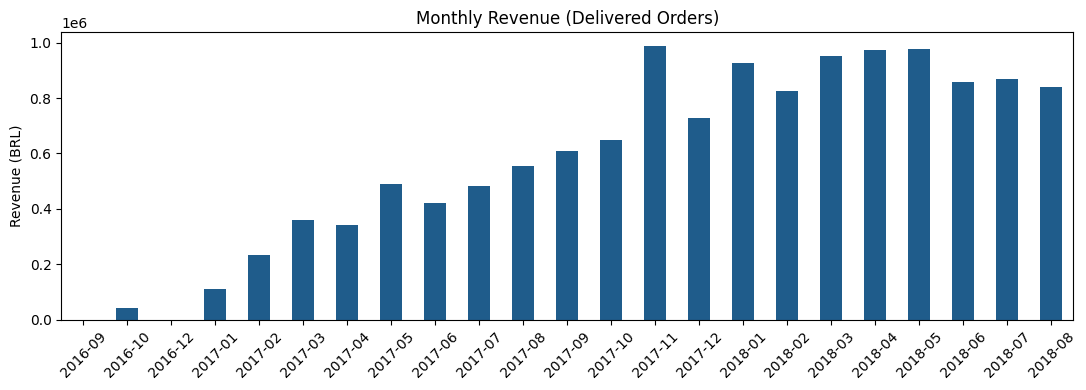

,month,n_orders,revenue,avg_basket
0,2016-09,1,134.97,134.97
1,2016-10,265,40325.11,152.17
2,2016-12,1,10.90,10.90
3,2017-01,750,111798.36,149.06
4,2017-02,1653,234223.40,141.70
5,2017-03,2546,359198.85,141.08
6,2017-04,2303,340669.68,147.92
7,2017-05,3546,489338.25,138.00
8,2017-06,3135,421923.37,134.58
9,2017-07,3872,481604.52,124.38


In [108]:
import pandas as pd
import matplotlib.pyplot as plt

monthly = pd.read_sql_query("""
SELECT
    TO_CHAR(o.order_purchase_timestamp, 'YYYY-MM') AS month,
    COUNT(DISTINCT o.order_id) AS n_orders,
    ROUND(SUM(i.price)::numeric, 2) AS revenue,
    ROUND(
        (SUM(i.price) / COUNT(DISTINCT o.order_id))::numeric, 2
    ) AS avg_basket
FROM orders o
JOIN order_items i
    ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY TO_CHAR(o.order_purchase_timestamp, 'YYYY-MM')
ORDER BY month;
""", engine)

print("Total delivered revenue:", f"{monthly['revenue'].sum():,.2f} BRL")

ax = monthly.plot(
    x="month",
    y="revenue",
    kind="bar",
    figsize=(11, 4),
    legend=False,
    color="#1f5c8b"
)

ax.set_title("Monthly Revenue (Delivered Orders)")
ax.set_xlabel("")
ax.set_ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly)

The first and last months are incomplete in the dataset, and there are no delivered orders in November 2016. These are data artefacts, not real trends.

# 4. Month-over-month growth with LAG()

In [109]:
growth = q("""
WITH monthly_revenue AS (
    SELECT TO_CHAR(o.order_purchase_timestamp, 'YYYY-MM') AS month,
           SUM(i.price) AS revenue
    FROM orders o
    JOIN order_items i ON o.order_id = i.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY 1
),
monthly_growth AS (
    SELECT month, revenue,
           LAG(revenue) OVER (ORDER BY month) AS previous_month_revenue
    FROM monthly_revenue
)
SELECT month,
       ROUND(revenue::numeric, 2) AS revenue,
       ROUND(previous_month_revenue::numeric, 2) AS previous_month_revenue,
       ROUND((
           100.0 * (revenue - previous_month_revenue)
           / NULLIF(previous_month_revenue, 0)
       )::numeric, 2) AS growth_pct
FROM monthly_growth
WHERE month BETWEEN '2017-01' AND '2018-08'
ORDER BY month;
""")
growth


,month,revenue,previous_month_revenue,growth_pct
0,2017-01,111798.36,10.90,1025573.03
1,2017-02,234223.40,111798.36,109.51
2,2017-03,359198.85,234223.40,53.36
3,2017-04,340669.68,359198.85,-5.16
4,2017-05,489338.25,340669.68,43.64
5,2017-06,421923.37,489338.25,-13.78
6,2017-07,481604.52,421923.37,14.15
7,2017-08,554699.70,481604.52,15.18
8,2017-09,607399.67,554699.70,9.50
9,2017-10,648247.65,607399.67,6.73


## 5. RFM segmentation

Each real customer is described by three measures: Recency (days since the last purchase), Frequency (number of orders) and Monetary value (total spent).

Segment names used here, with the French labels of the GitHub README:




| English | French |
| :--- | :--- |
| **This notebook** | **README (French)** |
| Recent big spenders | Gros acheteurs récents |
| At risk (high value) | À risque (gros montant) |
| Occasional | Occasionnels |
| Lost | Perdus |
| New customers | Nouveaux clients |
| Loyal active | Fidèles actifs |
| Loyal dormant | Fidèles endormis |


In [110]:
segments = pd.read_sql_query("""
WITH base AS (
    SELECT
        c.customer_unique_id,
        o.order_id,
        o.order_purchase_timestamp,
        SUM(i.price) AS order_amount
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN order_items i ON o.order_id = i.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id, o.order_id, o.order_purchase_timestamp
),
ref AS (
    SELECT MAX(order_purchase_timestamp) AS ref_date
    FROM base
),
rfm AS (
    SELECT
        b.customer_unique_id,
        CAST(EXTRACT(EPOCH FROM (
            (SELECT ref_date FROM ref) - MAX(b.order_purchase_timestamp)
        )) / 86400 AS INTEGER) AS recency_days,
        COUNT(DISTINCT b.order_id) AS frequency,
        SUM(b.order_amount) AS total_amount
    FROM base b
    GROUP BY b.customer_unique_id
),
scores AS (
    SELECT *,
        NTILE(5) OVER (ORDER BY recency_days DESC) AS r_score,
        NTILE(5) OVER (ORDER BY total_amount ASC) AS m_score
    FROM rfm
),
labelled AS (
    SELECT *,
        CASE
            WHEN frequency >= 2 AND r_score >= 3 THEN 'Loyal active'
            WHEN frequency >= 2 THEN 'Loyal dormant'
            WHEN r_score >= 4 AND m_score >= 4 THEN 'Recent big spenders'
            WHEN r_score >= 4 THEN 'New customers'
            WHEN r_score <= 2 AND m_score >= 4 THEN 'At risk (high value)'
            WHEN r_score <= 2 THEN 'Lost'
            ELSE 'Occasional'
        END AS segment
    FROM scores
)
SELECT
    segment,
    COUNT(*) AS n_customers,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM labelled), 2) AS pct_customers,
    ROUND(SUM(total_amount)::numeric, 2) AS segment_revenue,
    ROUND(
        (100.0 * SUM(total_amount) /
        (SELECT SUM(total_amount) FROM labelled))::numeric, 2
    ) AS pct_revenue
FROM labelled
GROUP BY segment
ORDER BY segment_revenue DESC;
""", engine)

print("Customers segmented:", f"{segments['n_customers'].sum():,}")
display(segments)

Customers segmented: 93,358


,segment,n_customers,pct_customers,segment_revenue,pct_revenue
0,Recent big spenders,14456,15.48,3863378.18,29.22
1,At risk (high value),13784,14.76,3817728.90,28.88
2,Occasional,18068,19.35,2351147.93,17.78
3,Lost,22564,24.17,1257002.94,9.51
4,New customers,21685,23.23,1203831.41,9.11
5,Loyal active,1805,1.93,479802.04,3.63
6,Loyal dormant,996,1.07,248606.71,1.88


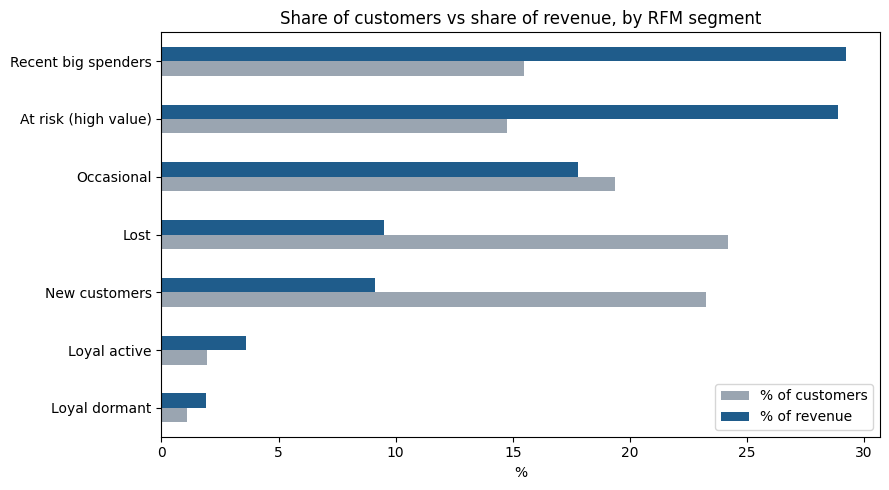

In [111]:
plot_df = segments.set_index("segment")[["pct_customers", "pct_revenue"]].sort_values("pct_revenue")
ax = plot_df.plot.barh(figsize=(9, 5), color=["#9aa5b1", "#1f5c8b"])
ax.set_title("Share of customers vs share of revenue, by RFM segment")
ax.set_xlabel("%")
ax.set_ylabel("")
ax.legend(["% of customers", "% of revenue"])
plt.tight_layout()
plt.show()

**Reading the chart :** A segment whose revenue bar is much longer than its customer bar is worth protecting. Note that the "high value" segments weigh a lot partly by construction (they are defined as the top 40% of spenders), so the useful signal is the crossing with recency: many high-value customers have not come back for a long time.

## 6. Cohort retention

Customers are grouped by the month of their first order (their cohort). For each cohort, we measure the share that ordered again 1, 3 and 6 months later. The cohorts are limited to 2017-01 → 2018-02: earlier months are tiny, and later ones are too recent to observe month 6.

In [112]:
cohorts = pd.read_sql_query("""
WITH orders_by_month AS (
    SELECT
        c.customer_unique_id,
        TO_CHAR(o.order_purchase_timestamp, 'YYYY-MM') AS order_month
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
),
activity AS (
    SELECT
        customer_unique_id,
        order_month,
        MIN(order_month) OVER (PARTITION BY customer_unique_id) AS cohort
    FROM orders_by_month
),
offsets AS (
    SELECT
        customer_unique_id,
        cohort,
        (
            CAST(SUBSTRING(order_month, 1, 4) AS INTEGER) -
            CAST(SUBSTRING(cohort, 1, 4) AS INTEGER)
        ) * 12
        + (
            CAST(SUBSTRING(order_month, 6, 2) AS INTEGER) -
            CAST(SUBSTRING(cohort, 6, 2) AS INTEGER)
        ) AS month_offset
    FROM activity
)
SELECT
    cohort,
    COUNT(DISTINCT CASE WHEN month_offset = 0 THEN customer_unique_id END) AS cohort_size,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN month_offset = 1 THEN customer_unique_id END)
        / NULLIF(COUNT(DISTINCT CASE WHEN month_offset = 0 THEN customer_unique_id END), 0), 2) AS pct_back_m1,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN month_offset = 3 THEN customer_unique_id END)
        / NULLIF(COUNT(DISTINCT CASE WHEN month_offset = 0 THEN customer_unique_id END), 0), 2) AS pct_back_m3,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN month_offset = 6 THEN customer_unique_id END)
        / NULLIF(COUNT(DISTINCT CASE WHEN month_offset = 0 THEN customer_unique_id END), 0), 2) AS pct_back_m6
FROM offsets
WHERE cohort BETWEEN '2017-01' AND '2018-02'
GROUP BY cohort
ORDER BY cohort;
""", engine)

cohorts

,cohort,cohort_size,pct_back_m1,pct_back_m3,pct_back_m6
0,2017-01,717,0.28,0.14,0.42
1,2017-02,1628,0.18,0.12,0.25
2,2017-03,2503,0.44,0.40,0.16
3,2017-04,2256,0.62,0.18,0.35
4,2017-05,3451,0.46,0.29,0.41
5,2017-06,3037,0.49,0.43,0.36
6,2017-07,3752,0.53,0.24,0.32
7,2017-08,4057,0.69,0.27,0.30
8,2017-09,4004,0.70,0.27,0.22
9,2017-10,4328,0.72,0.09,0.21


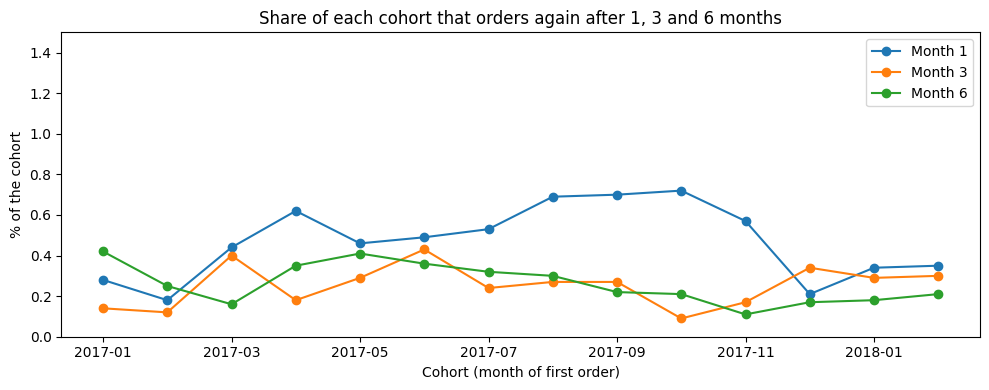

In [113]:
ax = cohorts.plot(x="cohort", y=["pct_back_m1", "pct_back_m3", "pct_back_m6"], kind="line", marker="o", figsize=(10, 4))
ax.set_title("Share of each cohort that orders again after 1, 3 and 6 months")
ax.set_xlabel("Cohort (month of first order)")
ax.set_ylabel("% of the cohort")
ax.set_ylim(0, 1.5)
ax.legend(["Month 1", "Month 3", "Month 6"])
plt.tight_layout()
plt.show()

**Reading the chart :** Every value is below 1%. The numbers behind them are tiny (a few dozen customers per cohort), so differences from one cohort to another are noise, not trends. One thing worth noting: the November 2017 cohort is the largest, which may reflect Black Friday (a hypothesis, not proven by this data).

## 7. Findings
Only about 3% of customers ordered more than once. The marketplace lives mostly on one-time buyers.
The "At risk (high value)" segment is about 14.7% of customers but about 28.8% of revenue. These are high spenders who have not come back for a long time.
Less than 1% of any cohort orders again after 1, 3 or 6 months.
Revenue stabilises at roughly 840,000 to 980,000 per month from March 2018.

## 8. Recommendations (business reading, not causal claims)
Run a reactivation campaign on the "At risk (high value)" segment. It is the group where a small number of customers carries a large share of revenue.
Investigate why so few customers return. This analysis describes the behaviour but does not explain it. Natural next steps are to cross it with review scores and delivery delays.
Treat the segment thresholds as adjustable. They are my own rules, so a business team should tune them.

## 9. Limits
2016–2018 data: the first and last months are incomplete.
The analysis is descriptive. It does not predict future customer behaviour.
Revenue excludes freight.